# k-Nearest Neighbours (k-NN)

**Idea:** to classify a new example, find the **k training examples closest to it**. They vote. The class with the most votes wins.

There is no training step. The model is just the training data.

What we test:
* **k** – how many neighbours vote
* **distance** – how we measure "close"
* **normalisation** – how we change the features before measuring distance
* **voting** – every neighbour has 1 vote, or closer neighbours get more weight

All code for k-NN is written by us (NumPy only, no sklearn).

## 1. Setup

In [1]:
import os
import sys

# The notebook is in a sub-folder. Go to the project folder (where common.py is).
if not os.path.exists("common.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common   # our shared file: load data, split, metrics, Kaggle file

common.set_seed(42)
os.makedirs("knn/outputs", exist_ok=True)

## 2. Load the data

We use the same 80% train / 20% validation split as every model of the team (`common.stratified_split`).

In [2]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")
print("image:     train", X_image.shape, " test", X_image_test.shape)
print("sentiment: train", X_sent.shape, " test", X_sent_test.shape)

DATA = {
    "image": (X_image, y_image),
    "sentiment": (X_sent, y_sent),
}


def prepare(task, preprocess):
    """Split into train / validation, then apply the preprocessing.
    The preprocessing statistics (mean, std) come from the train rows only."""
    X, y = DATA[task]
    train_idx, val_idx = common.stratified_split(y)
    stats = common.fit_preprocessing(X[train_idx], preprocess)
    X_train = common.apply_preprocessing(X[train_idx], preprocess, stats)
    X_val = common.apply_preprocessing(X[val_idx], preprocess, stats)
    return X_train, y[train_idx], X_val, y[val_idx]

image:     train (20000, 500)  test (5000, 500)
sentiment: train (12000, 768)  test (5000, 768)


## 3. Distance functions

Each function gets **one** example `x` and **all** training rows, and returns one distance per training row.

* **Euclidean:** straight-line distance. `sqrt(sum((a - b)^2))`
* **Manhattan:** sum of absolute differences. `sum(|a - b|)`
* **Cosine:** compares the *direction* of two vectors, not their length. `1 - (a·b) / (|a| |b|)`
* **Chi-squared:** made for histograms (values ≥ 0). First each row is changed so it sums to 1. Then `0.5 * sum((a - b)^2 / (a + b))`. A difference in a small bin counts more than the same difference in a big bin. The image features are ≥ 0 and look like histograms, so we try it for images only.

In [3]:
def euclidean(x, X_train):
    return np.sqrt(((X_train - x) ** 2).sum(axis=1))


def manhattan(x, X_train):
    return np.abs(X_train - x).sum(axis=1)


def cosine(x, X_train):
    dot = X_train @ x
    lengths = np.linalg.norm(X_train, axis=1) * np.linalg.norm(x)
    return 1 - dot / (lengths + 1e-12)          # + small number: never divide by 0


def chi_squared(x, X_train):
    p = x / (x.sum() + 1e-12)                                     # this example: sums to 1
    Q = X_train / (X_train.sum(axis=1, keepdims=True) + 1e-12)    # every training row: sums to 1
    return 0.5 * ((Q - p) ** 2 / (Q + p + 1e-12)).sum(axis=1)


DISTANCES = {
    "euclidean": euclidean,
    "manhattan": manhattan,
    "cosine": cosine,
    "chi_squared": chi_squared,
}

# Small check with two tiny vectors
a = np.array([1.0, 0.0, 2.0])
B = np.array([[1.0, 0.0, 2.0],     # same as a  -> distance 0
              [0.0, 1.0, 0.0]])
for name, f in DISTANCES.items():
    print(f"{name:<12}", np.round(f(a, B), 3))

euclidean    [0.    2.449]
manhattan    [0. 4.]
cosine       [0. 1.]
chi_squared  [0. 1.]


## 4. The k-NN classifier

Two steps:

1. **Find neighbours:** for every validation example, compute the distance to all training rows and keep the `max_k` closest ones (sorted, closest first).
2. **Vote:** the first `k` neighbours vote.
   * `power = 0` → every neighbour has 1 vote (unweighted)
   * `power > 0` → weight = `1 / distance^power` (closer neighbours count more; bigger power = even more)

   Example with `power = 8`: a neighbour at distance 0.5 gets 256 times more weight than one at distance 1.

Finding neighbours is the slow part. We do it **once** with the biggest k we test, and then try every k and every voting rule on the same neighbour list.

In [4]:
def find_neighbors(X_train, X_query, distance, max_k):
    neighbor_idx = np.zeros((len(X_query), max_k), dtype=int)
    neighbor_dist = np.zeros((len(X_query), max_k))
    for i in range(len(X_query)):
        d = distance(X_query[i], X_train)          # distance to every training row
        closest = np.argsort(d)[:max_k]            # row numbers of the max_k smallest distances
        neighbor_idx[i] = closest
        neighbor_dist[i] = d[closest]
    return neighbor_idx, neighbor_dist


def vote(neighbor_idx, neighbor_dist, y_train, k, n_classes, power=0):
    predictions = np.zeros(len(neighbor_idx), dtype=int)
    for i in range(len(neighbor_idx)):
        labels = y_train[neighbor_idx[i, :k]]                   # classes of the k closest neighbours
        if power == 0:
            weights = np.ones(k)                                # 1 vote each
        else:
            weights = 1 / (neighbor_dist[i, :k] + 1e-8) ** power
        votes = np.bincount(labels, weights=weights, minlength=n_classes)   # sum of the weights per class
        predictions[i] = np.argmax(votes)                       # class with the most votes
    return predictions

In [5]:
# Small example: 5 validation examples of the sentiment task, k = 5
X_tr, y_tr, X_va, y_va = prepare("sentiment", "standardize")
idx, dist = find_neighbors(X_tr, X_va[:5], cosine, max_k=5)
print("labels of the 5 neighbours:\n", y_tr[idx])
print("prediction:", vote(idx, dist, y_tr, 5, 3))
print("true label:", y_va[:5])

labels of the 5 neighbours:
 [[2 2 2 2 2]
 [1 0 1 0 2]
 [0 1 0 0 2]
 [1 2 1 1 0]
 [0 0 0 1 0]]
prediction: [2 0 0 1 0]
true label: [0 0 0 2 1]


## 5. Experiment helper

`test_knn` finds the neighbours (only once for each task + preprocessing + distance), tries every k, and saves the results in a table.

In [6]:
KS = {"image": [1, 3, 5, 10, 20, 50], "sentiment": [1, 3, 5, 10, 20, 50, 100]}
N_CLASSES = common.N_CLASSES          # {"image": 50, "sentiment": 3}

results = []          # one row per experiment
neighbor_lists = {}   # (task, preprocess, distance) -> neighbours of the validation rows


def test_knn(task, preprocess, distance_name, power=0):
    X_tr, y_tr, X_va, y_va = prepare(task, preprocess)
    key = (task, preprocess, distance_name)
    if key not in neighbor_lists:
        start = time.time()
        neighbor_lists[key] = find_neighbors(X_tr, X_va, DISTANCES[distance_name], max(KS[task]))
        print(f"   (neighbour search {time.time() - start:.0f}s)")
    idx, dist = neighbor_lists[key]

    accuracies = []
    for k in KS[task]:
        pred = vote(idx, dist, y_tr, k, N_CLASSES[task], power)
        acc = common.accuracy(y_va, pred)
        accuracies.append(acc)
        results.append({"task": task, "preprocess": preprocess, "distance": distance_name,
                        "power": power, "k": k, "val_acc": round(acc, 4)})
    text = "  ".join(f"k={k}: {a:.3f}" for k, a in zip(KS[task], accuracies))
    print(f"{preprocess:<12} {distance_name:<12} power={power}   {text}")
    return accuracies


def plot_curves(task, curves, title):
    plt.figure(figsize=(7, 4))
    for label, accuracies in curves.items():
        plt.plot(KS[task], accuracies, marker="o", label=label)
    plt.xscale("log")
    plt.xticks(KS[task], [str(k) for k in KS[task]])
    plt.xlabel("k (number of neighbours)")
    plt.ylabel("validation accuracy")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.show()

## 6. Image task (50 classes)

### 6.1 Distance function (raw features)

   (neighbour search 130s)
none         euclidean    power=0   k=1: 0.519  k=3: 0.424  k=5: 0.423  k=10: 0.393  k=20: 0.359  k=50: 0.307
   (neighbour search 349s)
none         manhattan    power=0   k=1: 0.405  k=3: 0.319  k=5: 0.280  k=10: 0.245  k=20: 0.207  k=50: 0.167
   (neighbour search 262s)
none         cosine       power=0   k=1: 0.519  k=3: 0.424  k=5: 0.424  k=10: 0.393  k=20: 0.359  k=50: 0.306
   (neighbour search 747s)
none         chi_squared  power=0   k=1: 0.579  k=3: 0.471  k=5: 0.469  k=10: 0.450  k=20: 0.409  k=50: 0.355


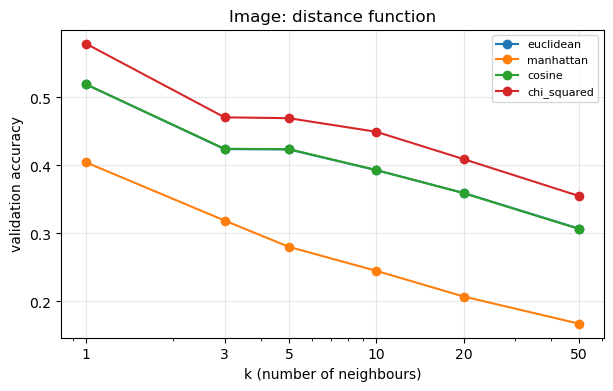

In [7]:
curves = {}
for name in ["euclidean", "manhattan", "cosine", "chi_squared"]:
    curves[name] = test_knn("image", "none", name)
plot_curves("image", curves, "Image: distance function")

### 6.2 Normalisation

* `none` – raw features
* `standardize` – every feature gets mean 0 and std 1
* `sqrt` – square root of every value, then every row gets length 1

(Chi-squared is not used here: after `standardize` some values are negative.)

none         euclidean    power=0   k=1: 0.519  k=3: 0.424  k=5: 0.423  k=10: 0.393  k=20: 0.359  k=50: 0.307
none         cosine       power=0   k=1: 0.519  k=3: 0.424  k=5: 0.424  k=10: 0.393  k=20: 0.359  k=50: 0.306
   (neighbour search 363s)
standardize  euclidean    power=0   k=1: 0.430  k=3: 0.350  k=5: 0.330  k=10: 0.302  k=20: 0.261  k=50: 0.217
   (neighbour search 222s)
standardize  cosine       power=0   k=1: 0.533  k=3: 0.421  k=5: 0.421  k=10: 0.396  k=20: 0.379  k=50: 0.334
   (neighbour search 364s)
sqrt         euclidean    power=0   k=1: 0.563  k=3: 0.464  k=5: 0.454  k=10: 0.434  k=20: 0.388  k=50: 0.333
   (neighbour search 159s)
sqrt         cosine       power=0   k=1: 0.563  k=3: 0.464  k=5: 0.454  k=10: 0.434  k=20: 0.388  k=50: 0.333


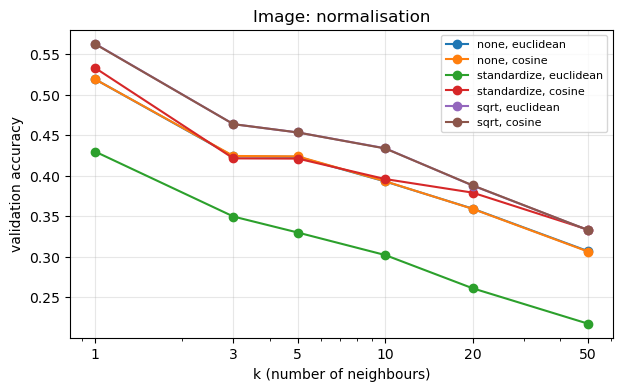

In [8]:
curves = {}
for preprocess in ["none", "standardize", "sqrt"]:
    for name in ["euclidean", "cosine"]:
        curves[f"{preprocess}, {name}"] = test_knn("image", preprocess, name)
plot_curves("image", curves, "Image: normalisation")

### 6.3 Weighted voting

We use the best pair from above. **Change these two lines if your table says something else.**

Chi-squared distances between neighbours are very close to each other, so we also try big powers (16, 24): only the very closest neighbours really count.

none         chi_squared  power=0   k=1: 0.579  k=3: 0.471  k=5: 0.469  k=10: 0.450  k=20: 0.409  k=50: 0.355
none         chi_squared  power=1   k=1: 0.579  k=3: 0.572  k=5: 0.553  k=10: 0.509  k=20: 0.470  k=50: 0.396
none         chi_squared  power=4   k=1: 0.579  k=3: 0.578  k=5: 0.572  k=10: 0.550  k=20: 0.531  k=50: 0.480
none         chi_squared  power=8   k=1: 0.579  k=3: 0.584  k=5: 0.587  k=10: 0.581  k=20: 0.576  k=50: 0.560
none         chi_squared  power=16   k=1: 0.579  k=3: 0.586  k=5: 0.590  k=10: 0.590  k=20: 0.597  k=50: 0.598
none         chi_squared  power=24   k=1: 0.579  k=3: 0.586  k=5: 0.591  k=10: 0.593  k=20: 0.596  k=50: 0.601


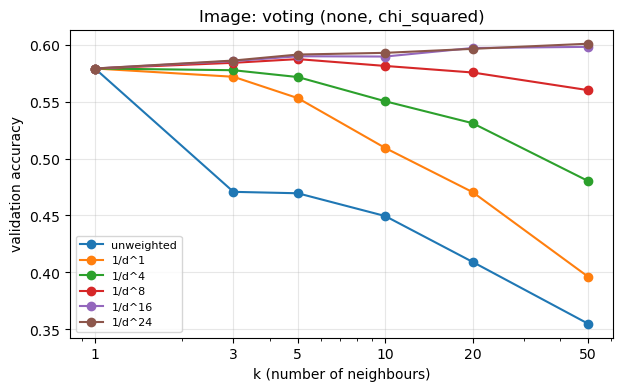

In [9]:
IMAGE_PREPROCESS = "none"
IMAGE_DISTANCE = "chi_squared"

curves = {}
for power in [0, 1, 4, 8, 16, 24]:
    label = "unweighted" if power == 0 else f"1/d^{power}"
    curves[label] = test_knn("image", IMAGE_PREPROCESS, IMAGE_DISTANCE, power)
plot_curves("image", curves, f"Image: voting ({IMAGE_PREPROCESS}, {IMAGE_DISTANCE})")

### 6.4 Train vs validation accuracy

With **k = 1**, every training example finds **itself** as its closest neighbour, so training accuracy is 100%. This is **overfitting**: the model memorises the training data. Bigger k makes the decision smoother.

(We check 1000 training rows to save time.)

k =   1   train 1.000   validation 0.579
k =   3   train 0.770   validation 0.471
k =   5   train 0.726   validation 0.469
k =  10   train 0.653   validation 0.450
k =  20   train 0.571   validation 0.409
k =  50   train 0.484   validation 0.355


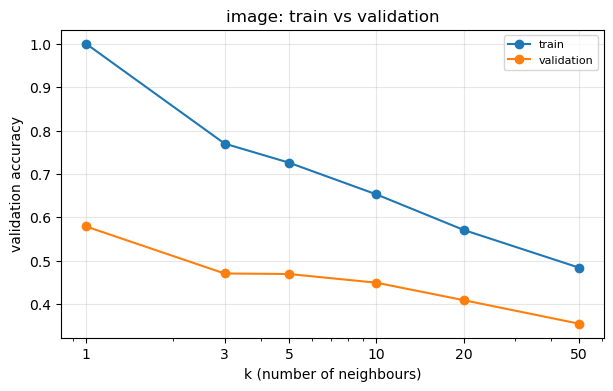

In [10]:
def train_vs_validation(task, preprocess, distance_name):
    X_tr, y_tr, X_va, y_va = prepare(task, preprocess)
    check = np.random.default_rng(42).choice(len(X_tr), 1000, replace=False)
    train_idx, train_dist = find_neighbors(X_tr, X_tr[check], DISTANCES[distance_name], max(KS[task]))
    val_idx, val_dist = neighbor_lists[(task, preprocess, distance_name)]

    train_acc, val_acc = [], []
    for k in KS[task]:
        train_acc.append(common.accuracy(y_tr[check], vote(train_idx, train_dist, y_tr, k, N_CLASSES[task])))
        val_acc.append(common.accuracy(y_va, vote(val_idx, val_dist, y_tr, k, N_CLASSES[task])))
        print(f"k = {k:3d}   train {train_acc[-1]:.3f}   validation {val_acc[-1]:.3f}")
    plot_curves(task, {"train": train_acc, "validation": val_acc}, f"{task}: train vs validation")


train_vs_validation("image", IMAGE_PREPROCESS, IMAGE_DISTANCE)

## 7. Sentiment task (3 classes)

The BERT features can be negative, so chi-squared cannot be used here.

### 7.1 Distance function (raw features)

   (neighbour search 130s)
none         euclidean    power=0   k=1: 0.488  k=3: 0.510  k=5: 0.534  k=10: 0.550  k=20: 0.571  k=50: 0.575  k=100: 0.584
   (neighbour search 115s)
none         manhattan    power=0   k=1: 0.497  k=3: 0.502  k=5: 0.533  k=10: 0.555  k=20: 0.574  k=50: 0.578  k=100: 0.578
   (neighbour search 37s)
none         cosine       power=0   k=1: 0.487  k=3: 0.515  k=5: 0.526  k=10: 0.558  k=20: 0.575  k=50: 0.586  k=100: 0.571


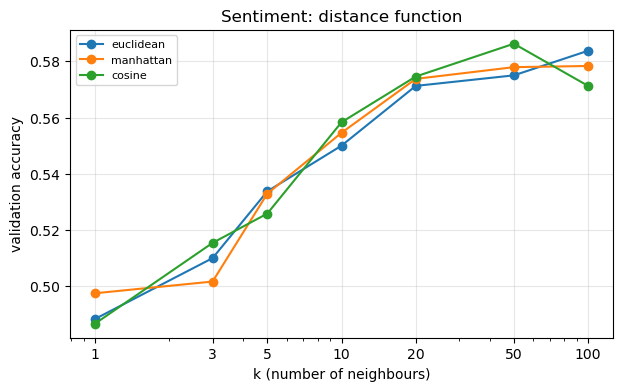

In [11]:
curves = {}
for name in ["euclidean", "manhattan", "cosine"]:
    curves[name] = test_knn("sentiment", "none", name)
plot_curves("sentiment", curves, "Sentiment: distance function")

### 7.2 Normalisation

none         euclidean    power=0   k=1: 0.488  k=3: 0.510  k=5: 0.534  k=10: 0.550  k=20: 0.571  k=50: 0.575  k=100: 0.584
none         cosine       power=0   k=1: 0.487  k=3: 0.515  k=5: 0.526  k=10: 0.558  k=20: 0.575  k=50: 0.586  k=100: 0.571
   (neighbour search 54s)
standardize  euclidean    power=0   k=1: 0.490  k=3: 0.512  k=5: 0.535  k=10: 0.548  k=20: 0.579  k=50: 0.581  k=100: 0.581
   (neighbour search 33s)
standardize  cosine       power=0   k=1: 0.488  k=3: 0.516  k=5: 0.543  k=10: 0.559  k=20: 0.571  k=50: 0.586  k=100: 0.586


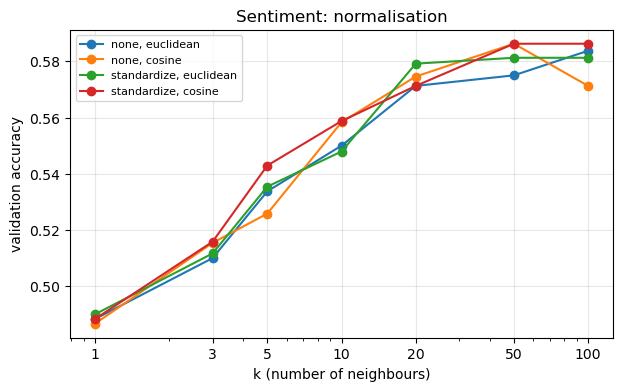

In [12]:
curves = {}
for preprocess in ["none", "standardize"]:
    for name in ["euclidean", "cosine"]:
        curves[f"{preprocess}, {name}"] = test_knn("sentiment", preprocess, name)
plot_curves("sentiment", curves, "Sentiment: normalisation")

### 7.3 Weighted voting

**Change these two lines if your table says something else.**

standardize  cosine       power=0   k=1: 0.488  k=3: 0.516  k=5: 0.543  k=10: 0.559  k=20: 0.571  k=50: 0.586  k=100: 0.586
standardize  cosine       power=1   k=1: 0.488  k=3: 0.516  k=5: 0.541  k=10: 0.558  k=20: 0.572  k=50: 0.589  k=100: 0.586
standardize  cosine       power=4   k=1: 0.488  k=3: 0.516  k=5: 0.537  k=10: 0.557  k=20: 0.579  k=50: 0.594  k=100: 0.600
standardize  cosine       power=8   k=1: 0.488  k=3: 0.510  k=5: 0.528  k=10: 0.548  k=20: 0.570  k=50: 0.585  k=100: 0.588


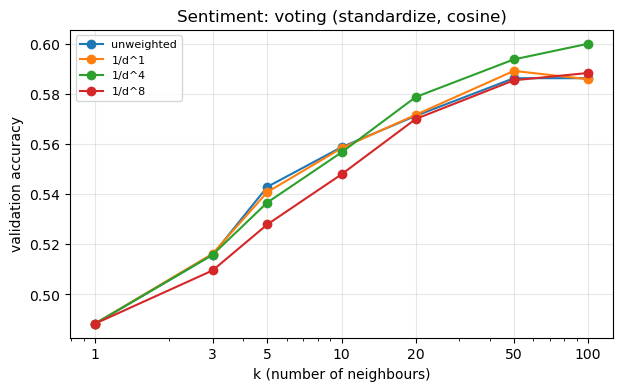

In [13]:
SENT_PREPROCESS = "standardize"
SENT_DISTANCE = "cosine"

curves = {}
for power in [0, 1, 4, 8]:
    label = "unweighted" if power == 0 else f"1/d^{power}"
    curves[label] = test_knn("sentiment", SENT_PREPROCESS, SENT_DISTANCE, power)
plot_curves("sentiment", curves, f"Sentiment: voting ({SENT_PREPROCESS}, {SENT_DISTANCE})")

### 7.4 Train vs validation accuracy

k =   1   train 1.000   validation 0.488
k =   3   train 0.754   validation 0.516
k =   5   train 0.704   validation 0.543
k =  10   train 0.671   validation 0.559
k =  20   train 0.657   validation 0.571
k =  50   train 0.619   validation 0.586
k = 100   train 0.597   validation 0.586


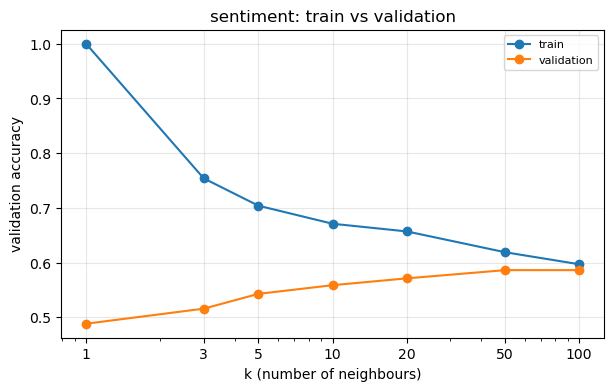

In [14]:
train_vs_validation("sentiment", SENT_PREPROCESS, SENT_DISTANCE)

## 8. Best settings

The 10 best rows of each task. The best row is used for the final model.

In [15]:
table = pd.DataFrame(results)
BEST = {}
for task in ["image", "sentiment"]:
    t = table[table["task"] == task].sort_values("val_acc", ascending=False)
    t.to_csv(f"knn/outputs/{task}_experiments.csv", index=False)
    display(t.head(10))
    best = t.iloc[0]
    BEST[task] = {"preprocess": best["preprocess"], "distance": best["distance"],
                  "k": int(best["k"]), "power": int(best["power"])}
    print(task, "best:", BEST[task], " validation accuracy", best["val_acc"])

,task,preprocess,distance,power,k,val_acc
95,image,none,chi_squared,24,50,0.6008
89,image,none,chi_squared,16,50,0.5980
88,image,none,chi_squared,16,20,0.5970
94,image,none,chi_squared,24,20,0.5962
93,image,none,chi_squared,24,10,0.5927
92,image,none,chi_squared,24,5,0.5913
86,image,none,chi_squared,16,5,0.5897
87,image,none,chi_squared,16,10,0.5895
80,image,none,chi_squared,8,5,0.5873
91,image,none,chi_squared,24,3,0.5860


image best: {'preprocess': 'none', 'distance': 'chi_squared', 'k': 50, 'power': 24}  validation accuracy 0.6008


,task,preprocess,distance,power,k,val_acc
165,sentiment,standardize,cosine,4,100,0.6000
164,sentiment,standardize,cosine,4,50,0.5938
157,sentiment,standardize,cosine,1,50,0.5892
172,sentiment,standardize,cosine,8,100,0.5883
143,sentiment,standardize,cosine,0,50,0.5863
144,sentiment,standardize,cosine,0,100,0.5863
129,sentiment,none,cosine,0,50,0.5863
150,sentiment,standardize,cosine,0,50,0.5863
151,sentiment,standardize,cosine,0,100,0.5863
115,sentiment,none,cosine,0,50,0.5863


sentiment best: {'preprocess': 'standardize', 'distance': 'cosine', 'k': 100, 'power': 4}  validation accuracy 0.6


## 9. Error analysis on the validation set

* **Confusion matrix:** row = true class, column = predicted class.
* **Recall** of a class: how many of its examples we found.
* **Precision** of a class: when we predict it, how often we are right.

sentiment: validation accuracy 0.6000


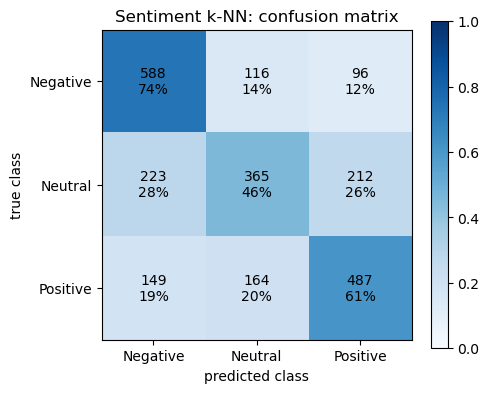

   Negative  recall 0.735   precision 0.613
   Neutral   recall 0.456   precision 0.566
   Positive  recall 0.609   precision 0.613
image: validation accuracy 0.6008


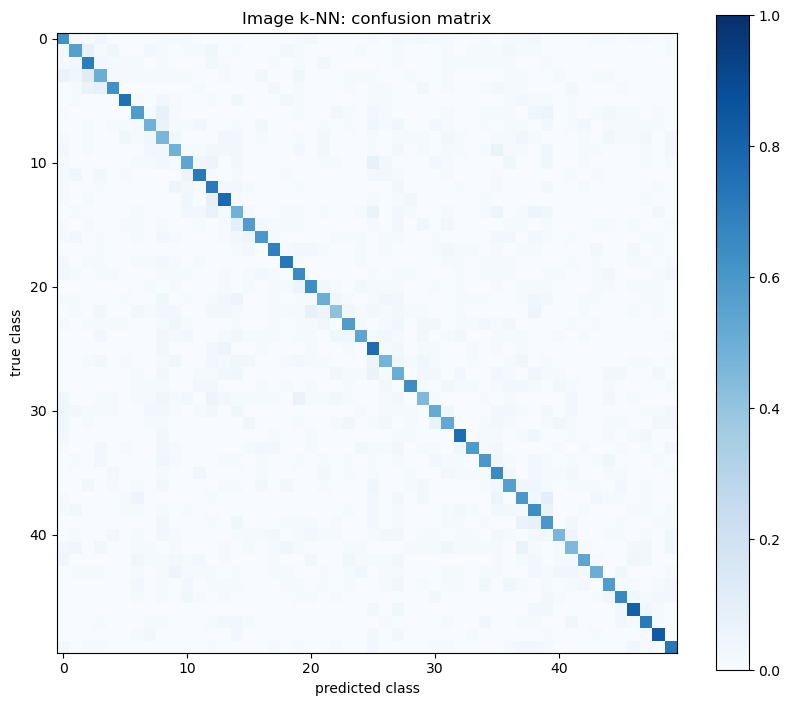

   5 hardest classes: [(22, 0.41), (29, 0.45), (41, 0.45), (40, 0.46), (8, 0.46)]
   5 easiest classes: [(25, 0.76), (32, 0.76), (13, 0.78), (46, 0.81), (48, 0.84)]
   most common mistakes (true class, predicted class, count):
       3 ->  2   9 times
      37 -> 39   8 times
      15 -> 14   7 times
       1 ->  2   6 times
       4 ->  3   6 times
       6 ->  8   6 times
      10 -> 25   6 times
      13 -> 12   6 times
      22 -> 20   6 times
      39 -> 38   6 times


In [16]:
def plot_confusion(cm, title, labels=None):
    shares = cm / cm.sum(axis=1, keepdims=True)     # every row sums to 1
    size = 5 if len(cm) <= 3 else 10
    plt.figure(figsize=(size, size * 0.85))
    plt.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar()
    if labels is not None:
        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)
        for i in range(len(cm)):
            for j in range(len(cm)):
                plt.text(j, i, f"{cm[i, j]}\n{shares[i, j]:.0%}", ha="center", va="center")
    plt.xlabel("predicted class")
    plt.ylabel("true class")
    plt.title(title)
    plt.show()


val_predictions = {}
for task in ["sentiment", "image"]:
    b = BEST[task]
    X_tr, y_tr, X_va, y_va = prepare(task, b["preprocess"])
    idx, dist = neighbor_lists[(task, b["preprocess"], b["distance"])]
    pred = vote(idx, dist, y_tr, b["k"], N_CLASSES[task], b["power"])
    val_predictions[task] = pred
    np.save(f"knn/outputs/{task}_val_pred.npy", pred)     # used by final/compare.ipynb
    print(f"{task}: validation accuracy {common.accuracy(y_va, pred):.4f}")

    cm = common.confusion_matrix(y_va, pred, N_CLASSES[task])
    if task == "sentiment":
        plot_confusion(cm, "Sentiment k-NN: confusion matrix", common.SENTIMENT_NAMES)
        recall = common.per_class_recall(cm)
        precision = common.per_class_precision(cm)
        for i, name in enumerate(common.SENTIMENT_NAMES):
            print(f"   {name:<9} recall {recall[i]:.3f}   precision {precision[i]:.3f}")
    else:
        plot_confusion(cm, "Image k-NN: confusion matrix")
        recall = common.per_class_recall(cm)
        order = np.argsort(recall)
        print("   5 hardest classes:", [(int(c), round(float(recall[c]), 2)) for c in order[:5]])
        print("   5 easiest classes:", [(int(c), round(float(recall[c]), 2)) for c in order[-5:]])
        print("   most common mistakes (true class, predicted class, count):")
        for true_c, pred_c, count in common.most_confused_pairs(cm, 10):
            print(f"      {true_c:2d} -> {pred_c:2d}   {count} times")

## 10. Test predictions for Kaggle

Now we use **all** training rows (train + validation) as neighbours, with the best settings.

In [17]:
TEST = {"image": (X_image_test, image_test_ids), "sentiment": (X_sent_test, sent_test_ids)}

for task in ["image", "sentiment"]:
    b = BEST[task]
    X, y = DATA[task]
    X_test, test_ids = TEST[task]
    stats = common.fit_preprocessing(X, b["preprocess"])          # statistics from all training rows
    X_all = common.apply_preprocessing(X, b["preprocess"], stats)
    X_test = common.apply_preprocessing(X_test, b["preprocess"], stats)

    start = time.time()
    idx, dist = find_neighbors(X_all, X_test, DISTANCES[b["distance"]], b["k"])
    pred = vote(idx, dist, y, b["k"], N_CLASSES[task], b["power"])
    pd.DataFrame({"id": test_ids, "label": pred}).to_csv(f"knn/outputs/{task}_test_pred.csv", index=False)
    print(f"{task}: saved knn/outputs/{task}_test_pred.csv  ({time.time() - start:.0f}s)")

image: saved knn/outputs/image_test_pred.csv  (834s)
sentiment: saved knn/outputs/sentiment_test_pred.csv  (272s)
